# I-JEPA observation lab

For my midterm project, I chose to study I-JEPA, which stands for Image-based Joint-Embedding Predictive Architecture. In this notebook, I follow one image through data preparation, the context and target encoders, the predictor, the loss, and one training step. I use the tensor shapes and weight changes to connect the code to the ideas from class.

The lab uses one NASA photograph, a fixed 64 × 64 crop, and 16 × 16 patches. The encoders and predictor come from Meta’s I-JEPA implementation and start with randomly initialized weights. The two encoders start with identical weights. The image and model sizes make it possible to follow individual patches through the code.

The notebook also compares two target sizes and three values of the moving-average momentum. The figures and measurements are from the CPU lab run. The research paper evaluates the representations learned through full pretraining.

This lab is based on the I-JEPA paper by Assran et al. (2023) and Meta’s implementation. Setup instructions are in README.md, and source credits are in SOURCES.md.

In [1]:
import json

from IPython.display import Image, display
import torch

from data_prep import DEFAULT_IMAGE, make_masks, plot_preparation, prepare_image
from loss_comparison import compare_losses, hand_examples, plot_loss_curves
from mask_comparison import compare_masks, plot_mask_comparison
from model import build_models, forward_pass, plot_architecture, plot_attention, shape_rows
from run_lab import PROJECT_DIR, run_lab
from train_step import plot_momentum, run_training_step

INITIALIZATION_SEED = 7
RESULTS_DIRECTORY = PROJECT_DIR / "outputs"
RESULTS_DIRECTORY.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
print("PyTorch:", torch.__version__)
print("Device: CPU; initialization seed:", INITIALIZATION_SEED)

PyTorch: 2.15.0+cpu
Device: CPU; initialization seed: 7


## 1. Data preparation

For this experiment, I used a photograph of astronaut Eileen Collins. The code takes a centered 410 × 410 region from the original 512 × 512 image and resizes it to 64 × 64. It scales the pixel values to [0, 1], normalizes each RGB channel using the ImageNet means and standard deviations, and puts the data in a tensor of shape `(1, 3, 64, 64)`. The axes are batch, channel, height, and width.

A 64 × 64 crop gives 64 / 16 = 4 patches along each side, so there are 16 patch positions altogether. The patches are numbered left to right, row by row. I use the four middle positions, 5, 6, 9, and 10, as the target block. The other twelve positions form the context. The masks are lists of patch indices. In the figure, the darkened patches show which positions are excluded from each selection.

The lab uses a fixed crop and target block so the same patch positions can be followed in each comparison. The released ImageNet pipeline samples random resized crops and target blocks during pretraining. In both cases, the image supplies the input for the context and target branches. The training reference comes from the target encoder's representation at the requested positions.

Image tensor: (1, 3, 64, 64)
Crop box in original pixels: (51, 51, 461, 461)
Context positions: [0, 1, 2, 3, 4, 7, 8, 11, 12, 13, 14, 15]
Target positions: [5, 6, 9, 10]


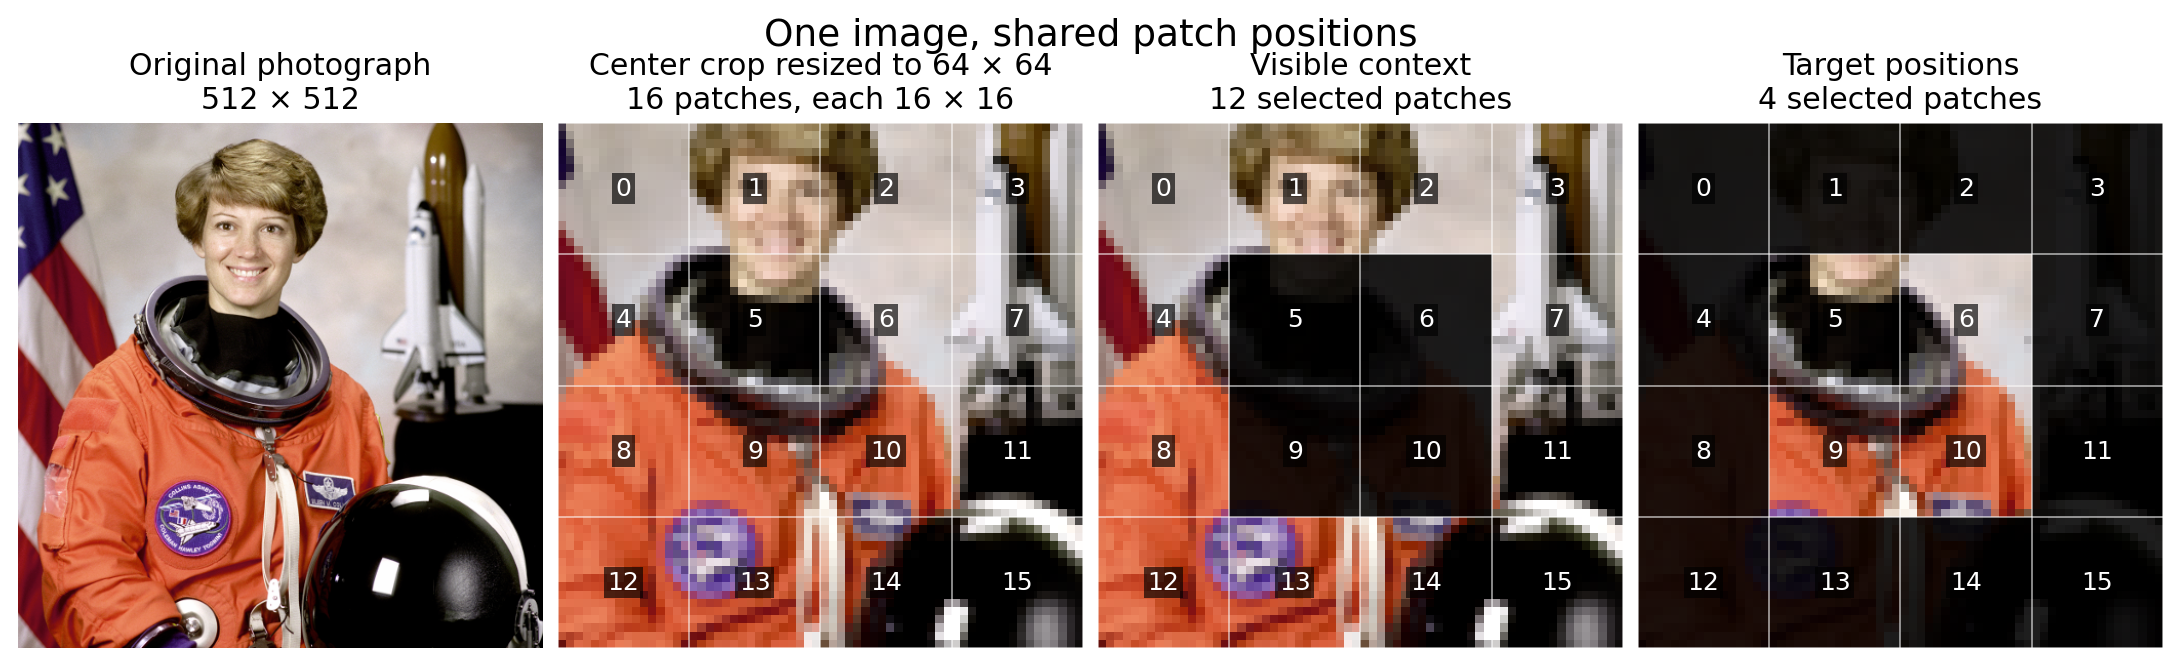

In [2]:
original_photograph, resized_crop, normalized_image_tensor, center_crop_coordinates = (
    prepare_image(DEFAULT_IMAGE)
)
context_patch_masks, target_patch_masks = make_masks()

print("Image tensor:", tuple(normalized_image_tensor.shape))
print("Crop box in original pixels:", center_crop_coordinates)
print("Context positions:", context_patch_masks[0][0].tolist())
print("Target positions:", target_patch_masks[0][0].tolist())
assert normalized_image_tensor.shape == (1, 3, 64, 64)
assert context_patch_masks[0].numel() == 12
assert target_patch_masks[0].numel() == 4

data_preparation_figure_path = RESULTS_DIRECTORY / "01_data_preparation.png"
plot_preparation(
    original_photograph,
    resized_crop,
    context_patch_masks,
    target_patch_masks,
    data_preparation_figure_path,
)
display(Image(filename=str(data_preparation_figure_path)))

## 2. Architecture and tensor flow

Both encoders start with the same image crop. The patch projection converts each of its 16 patches into a vector with 192 features. Each encoder adds positional information to these vectors. The context encoder keeps the twelve visible positions before its Transformer blocks, giving features of shape `(1, 12, 192)`. The target encoder processes all sixteen positions and gives `(1, 16, 192)`.

On the target side, the code normalizes the features and gathers the four vectors at the target positions. Because attention happens before gathering, a reference vector can include information from elsewhere in the image. On the context side, the predictor takes the twelve context vectors and projects them to width 96. It adds positional information and appends a mask token for each requested position. It processes all sixteen tokens, then projects the four target outputs back to width 192. The predictions and references both have shape `(1, 4, 192)`.

For one attention head, the calculation is shown below. Here d_k is the width of a key or query vector.

```text
Attention(Q, K, V) = softmax((Q × Kᵀ) / sqrt(d_k)) × V
```

The encoder width is 192 and there are three heads, so each head has width 192 / 3 = 64. For the context branch, multiplying a 12 × 64 query matrix by a 64 × 12 transposed key matrix gives a 12 × 12 score matrix. Including batch size and heads, the context attention tensor is `(1, 3, 12, 12)`. The target encoder and predictor each have a 16 × 16 attention matrix per head. The predictor's head width is 96 / 3 = 32.

The heatmaps show the first head in the first layer of each component, before the training step. A row shows how one query distributes its attention across the available keys after softmax.

patch_tokens                 (1, 16, 192)
context_features             (1, 12, 192)
target_features              (1, 16, 192)
references                   (1, 4, 192)
predictions                  (1, 4, 192)
Target encoder attention     (1, 3, 16, 16)
Context encoder attention    (1, 3, 12, 12)
Predictor attention          (1, 3, 16, 16)


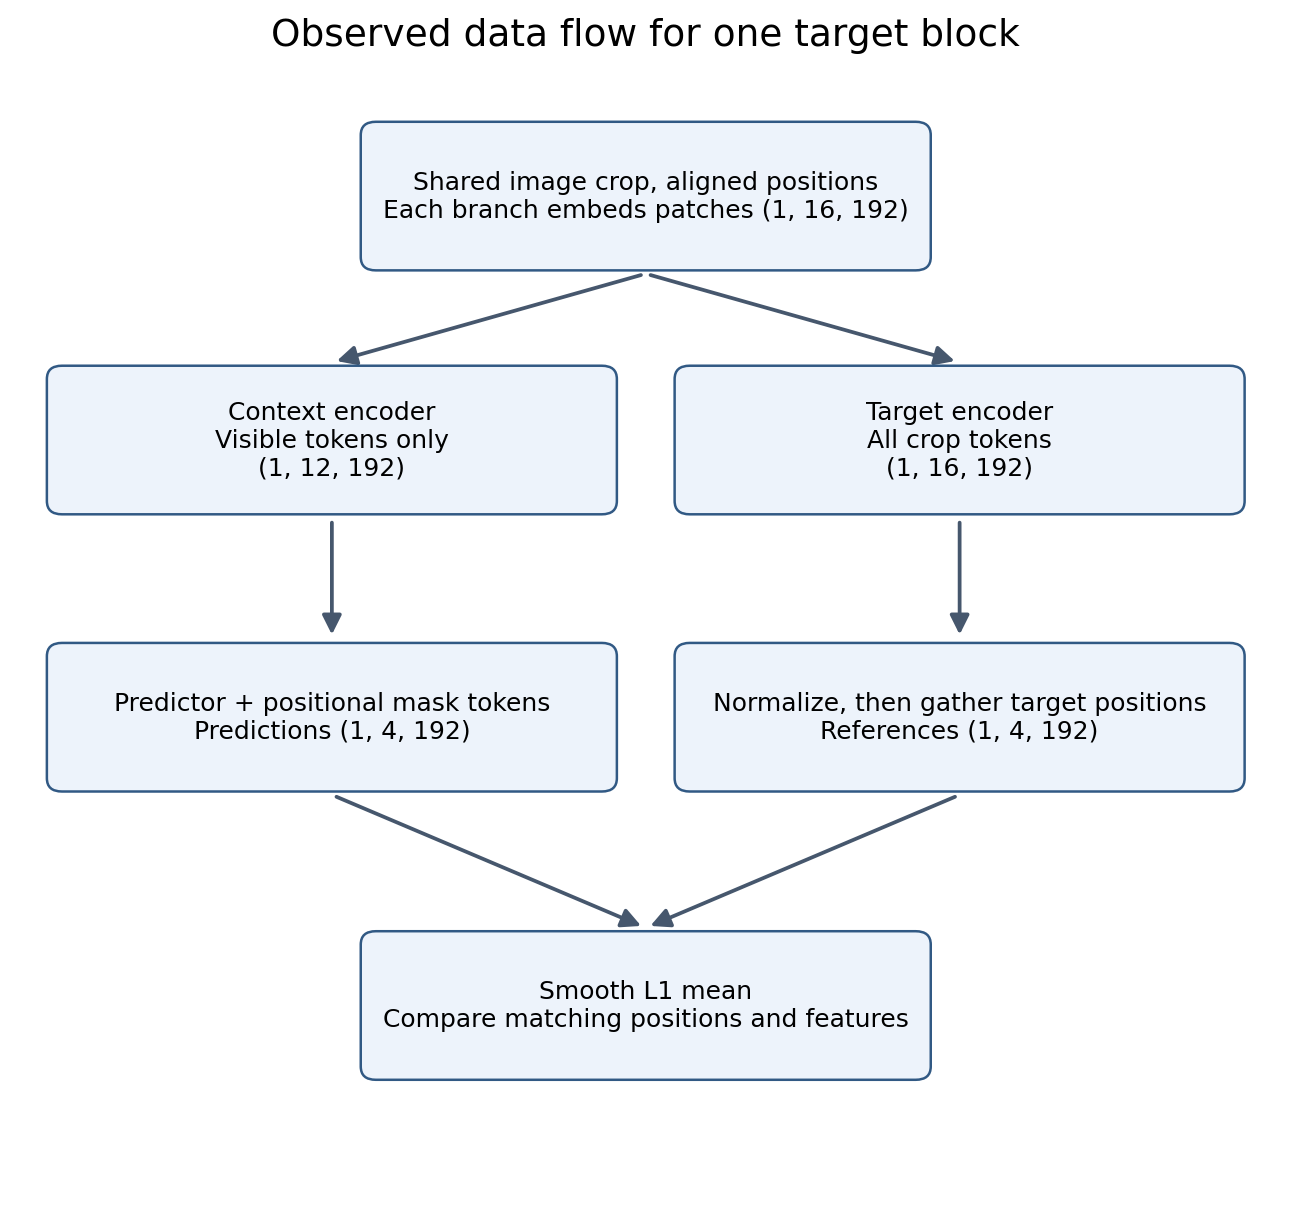

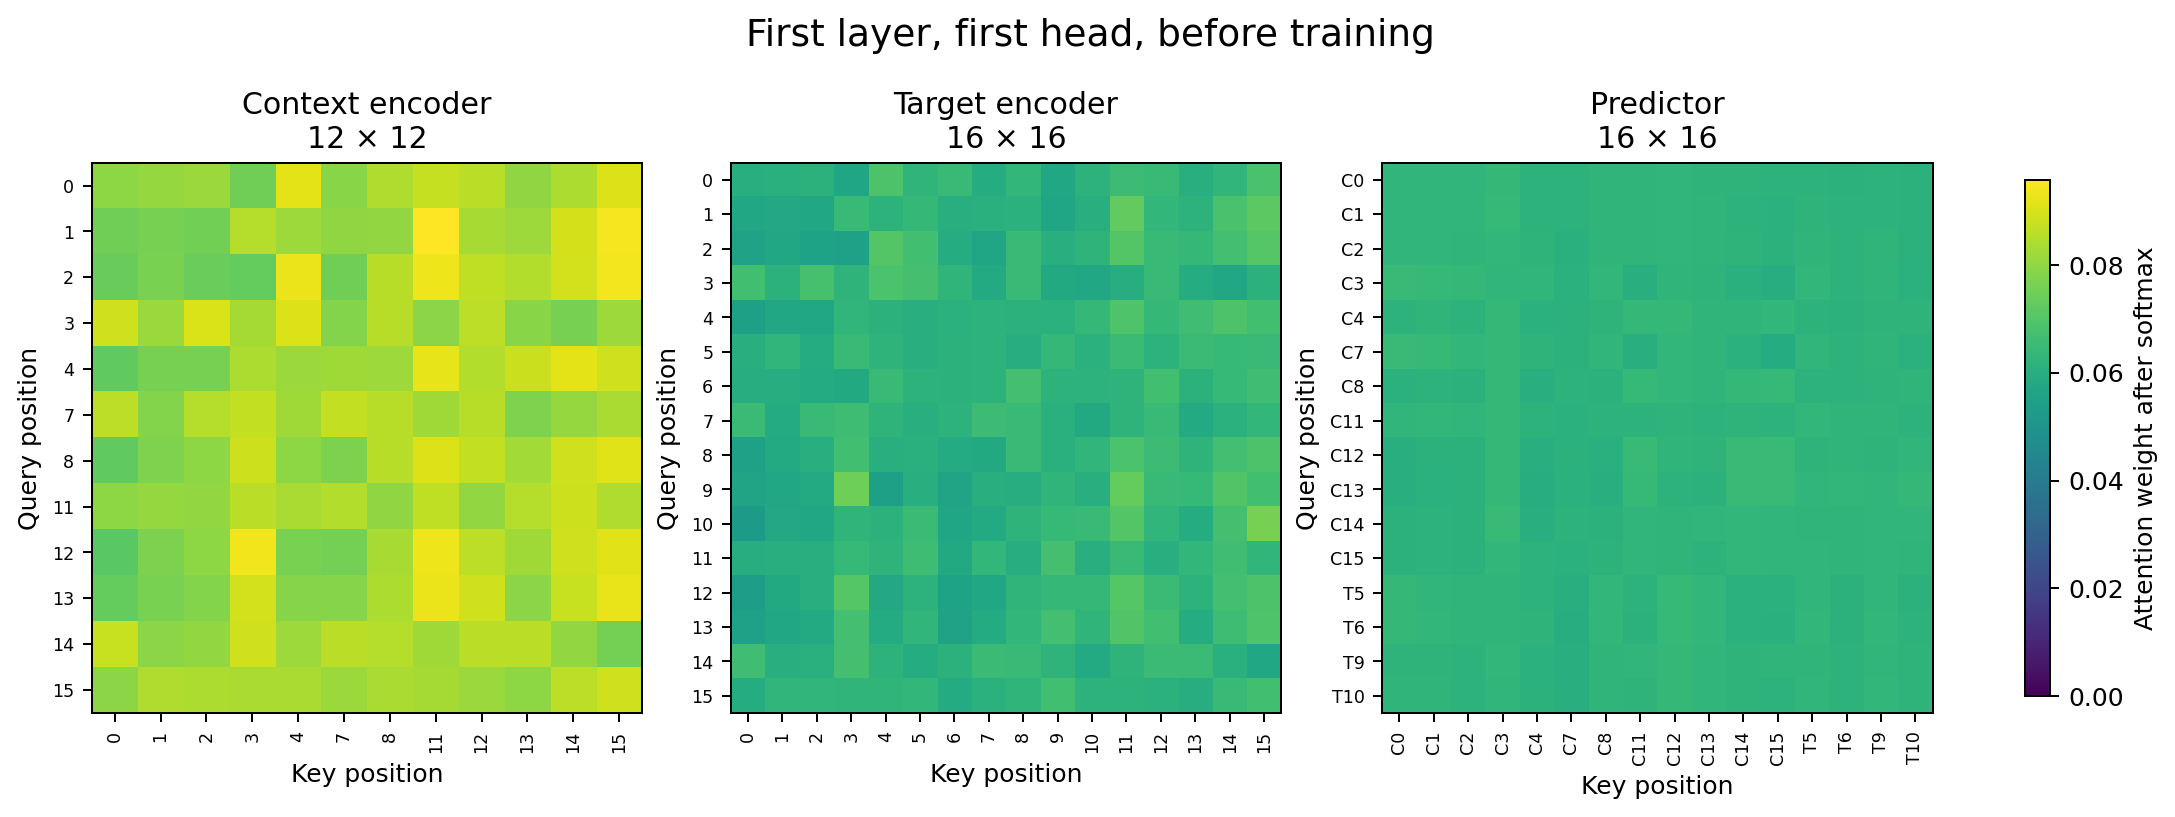

In [3]:
lab_models = build_models(seed=INITIALIZATION_SEED)
with torch.no_grad():
    baseline_model_outputs = forward_pass(
        lab_models, normalized_image_tensor, context_patch_masks, target_patch_masks
    )

for component_shape in shape_rows(baseline_model_outputs):
    print(f"{component_shape['component']:28s} {tuple(component_shape['shape'])}")

predicted_target_features = baseline_model_outputs["predictions"]
target_encoder_references = baseline_model_outputs["references"]
assert predicted_target_features.shape == target_encoder_references.shape == (1, 4, 192)

for attention_weight_tensor in baseline_model_outputs["attention"].values():
    # Softmax gives each query a row of weights that sums to one.
    attention_weight_row_sums = attention_weight_tensor.sum(dim=-1)
    torch.testing.assert_close(
        attention_weight_row_sums, torch.ones_like(attention_weight_row_sums)
    )

architecture_figure_path = RESULTS_DIRECTORY / "02_architecture_flow.png"
attention_weights_figure_path = RESULTS_DIRECTORY / "03_attention_weights.png"
plot_architecture(baseline_model_outputs, architecture_figure_path)
plot_attention(
    baseline_model_outputs,
    context_patch_masks,
    target_patch_masks,
    attention_weights_figure_path,
)
display(Image(filename=str(architecture_figure_path), width=650))
display(Image(filename=str(attention_weights_figure_path)))

## 3. Loss functions

The loss compares a predicted feature with the reference feature at the same patch position. I use `e` for the prediction minus the reference. For the single target block `T` in this experiment, the squared L2 objective from the paper is

```text
Squared L2 = sum over j in T of ‖prediction[j] − reference[j]‖²
```

This adds the squared residuals across the 4 × 192 = 768 features in the target block. The released code uses the mean of the Smooth L1 penalties. With the threshold set to 1, the penalty for one feature is

```text
Smooth L1(e) = 0.5 × e²      when |e| < 1
               |e| − 0.5    when |e| ≥ 1
```

I included a two-feature example to show how the two penalties respond to the same errors. With residuals of 0.5 and −2, the squared sum is 0.25 + 4 = 4.25. The Smooth L1 penalties are 0.125 and 1.5, so their mean is 0.8125. Changing −2 to −4 raises the squared sum to 16.25 and the Smooth L1 mean to 1.8125.

The left plot shows each feature's penalty and the right plot shows its derivative before averaging. For residual magnitudes beyond 1, the squared-error derivative keeps growing in magnitude and the Smooth L1 derivative has magnitude 1. The output also includes mean squared error so the two penalty rules can be compared using the same reduction.

{
  "feature_count": 768,
  "paper_squared_l2_sum": 786.4671020507812,
  "squared_error_mean": 1.024045705795288,
  "released_smooth_l1_mean": 0.4397709369659424
}

Two-coordinate examples
{'first_residual': 0.5, 'second_residual': -2.0, 'squared_l2_sum': 4.25, 'squared_error_mean': 2.125, 'smooth_l1_mean': 0.8125}
{'first_residual': 0.5, 'second_residual': -4.0, 'squared_l2_sum': 16.25, 'squared_error_mean': 8.125, 'smooth_l1_mean': 1.8125}


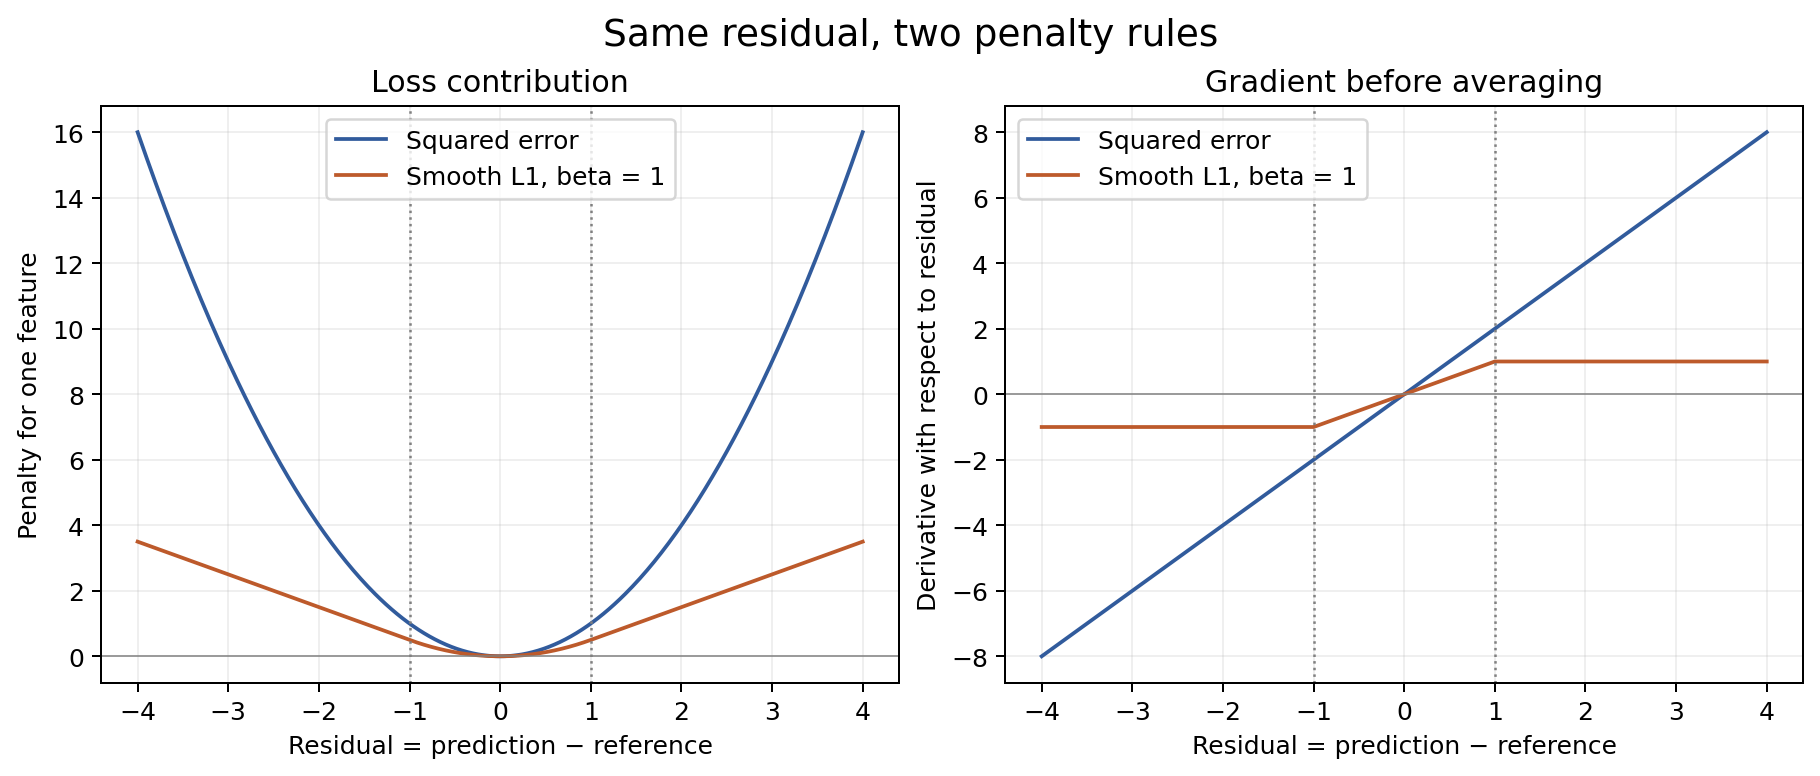

In [4]:
baseline_loss_values = compare_losses(predicted_target_features, target_encoder_references)
print(json.dumps(baseline_loss_values, indent=2))

two_coordinate_loss_examples = hand_examples()
print("\nTwo-coordinate examples")
for loss_example in two_coordinate_loss_examples:
    print(loss_example)

assert two_coordinate_loss_examples[0]["squared_l2_sum"] == 4.25
assert two_coordinate_loss_examples[0]["smooth_l1_mean"] == 0.8125
assert two_coordinate_loss_examples[1]["smooth_l1_mean"] == 1.8125

loss_curves_figure_path = RESULTS_DIRECTORY / "04_loss_curves.png"
plot_loss_curves(loss_curves_figure_path)
display(Image(filename=str(loss_curves_figure_path)))

## 4. Backpropagation and AdamW

The training step calculates Smooth L1 again with gradient recording enabled for the context encoder and predictor. The target encoder runs inside `torch.no_grad()` with its parameters set to `requires_grad=False`. Calling `backward()` computes the gradients. AdamW uses them to update the context encoder and predictor, with a fixed learning rate of 0.001 and weight decay of 0.04 for this step.

The output shows 148 context-encoder parameter tensors with gradients and 31 predictor parameter tensors with gradients. The target encoder has zero parameter tensors with gradients. A parameter tensor can contain many weights, so each count refers to a tensor as a whole.

I track the patch projection weight in each encoder and the output projection weight in the predictor. The tracked context and predictor weights change during AdamW. The tracked target weight has zero change at that point and moves when the moving-average update is applied. This shows where the gradient calculation ends and how the target encoder receives its update.

In [5]:
training_step_results = run_training_step(
    lab_models, normalized_image_tensor, context_patch_masks, target_patch_masks
)
component_update_measurements = training_step_results["components"]
for component_measurement in component_update_measurements:
    print(json.dumps(component_measurement, indent=2))

(
    context_encoder_measurements,
    predictor_measurements,
    target_encoder_measurements,
) = component_update_measurements

assert context_encoder_measurements["parameter_tensors_with_gradients"] > 0
assert predictor_measurements["parameter_tensors_with_gradients"] > 0
assert target_encoder_measurements["parameter_tensors_with_gradients"] == 0

# The target weight changes during the moving-average update.
assert target_encoder_measurements["tracked_change_after_adamw_l2"] == 0.0
assert target_encoder_measurements["tracked_change_after_ema_l2"] > 0.0

baseline_smooth_l1_loss = baseline_loss_values["released_smooth_l1_mean"]
training_loss_before_update = training_step_results["smooth_l1_before_update"]
assert abs(training_loss_before_update - baseline_smooth_l1_loss) < 1e-6

{
  "component": "Context encoder",
  "tracked_parameter": "patch_embed.proj.weight",
  "parameter_tensors_with_gradients": 148,
  "gradient_l2_all_parameters": 0.00359026319347322,
  "tracked_change_after_adamw_l2": 0.37880757451057434,
  "tracked_change_after_ema_l2": 0.37880757451057434
}
{
  "component": "Predictor",
  "tracked_parameter": "predictor_proj.weight",
  "parameter_tensors_with_gradients": 31,
  "gradient_l2_all_parameters": 0.3450950086116791,
  "tracked_change_after_adamw_l2": 0.13576291501522064,
  "tracked_change_after_ema_l2": 0.13576291501522064
}
{
  "component": "Target encoder",
  "tracked_parameter": "patch_embed.proj.weight",
  "parameter_tensors_with_gradients": 0,
  "gradient_l2_all_parameters": 0.0,
  "tracked_change_after_adamw_l2": 0.0,
  "tracked_change_after_ema_l2": 0.003788064233958721
}


## 5. Moving-average comparison

After AdamW updates the context encoder, the target encoder moves toward those updated weights. The update gives weight `m` to the old target parameters and weight 1 − m to the updated context parameters.

```text
target_new = m × target_old + (1 − m) × context_updated
```

Subtracting the old target weights gives

```text
target_new − target_old = (1 − m) × (context_updated − target_old)
```

The target moves a fraction 1 − m of the gap in one update. I compare 0.90, 0.99, and 0.999 using the same old target weights and the same updated context weights each time. The measured fractions are 0.1, 0.01, and 0.001. For these choices of momentum, each increase reduces the movement by a factor of ten.

The training step uses `m = 0.99`. The tracked target kernel moves about 0.003788 in L2 norm, and the target gradient fields are still empty because the moving average assigns the parameter values directly. The left plot shows the absolute movement and the right plot compares the measured fraction of the gap with 1 − m.

m=0.9    movement=0.03788079  gap fraction=0.100000
m=0.99   movement=0.00378806  gap fraction=0.010000
m=0.999  movement=0.00037880  gap fraction=0.001000


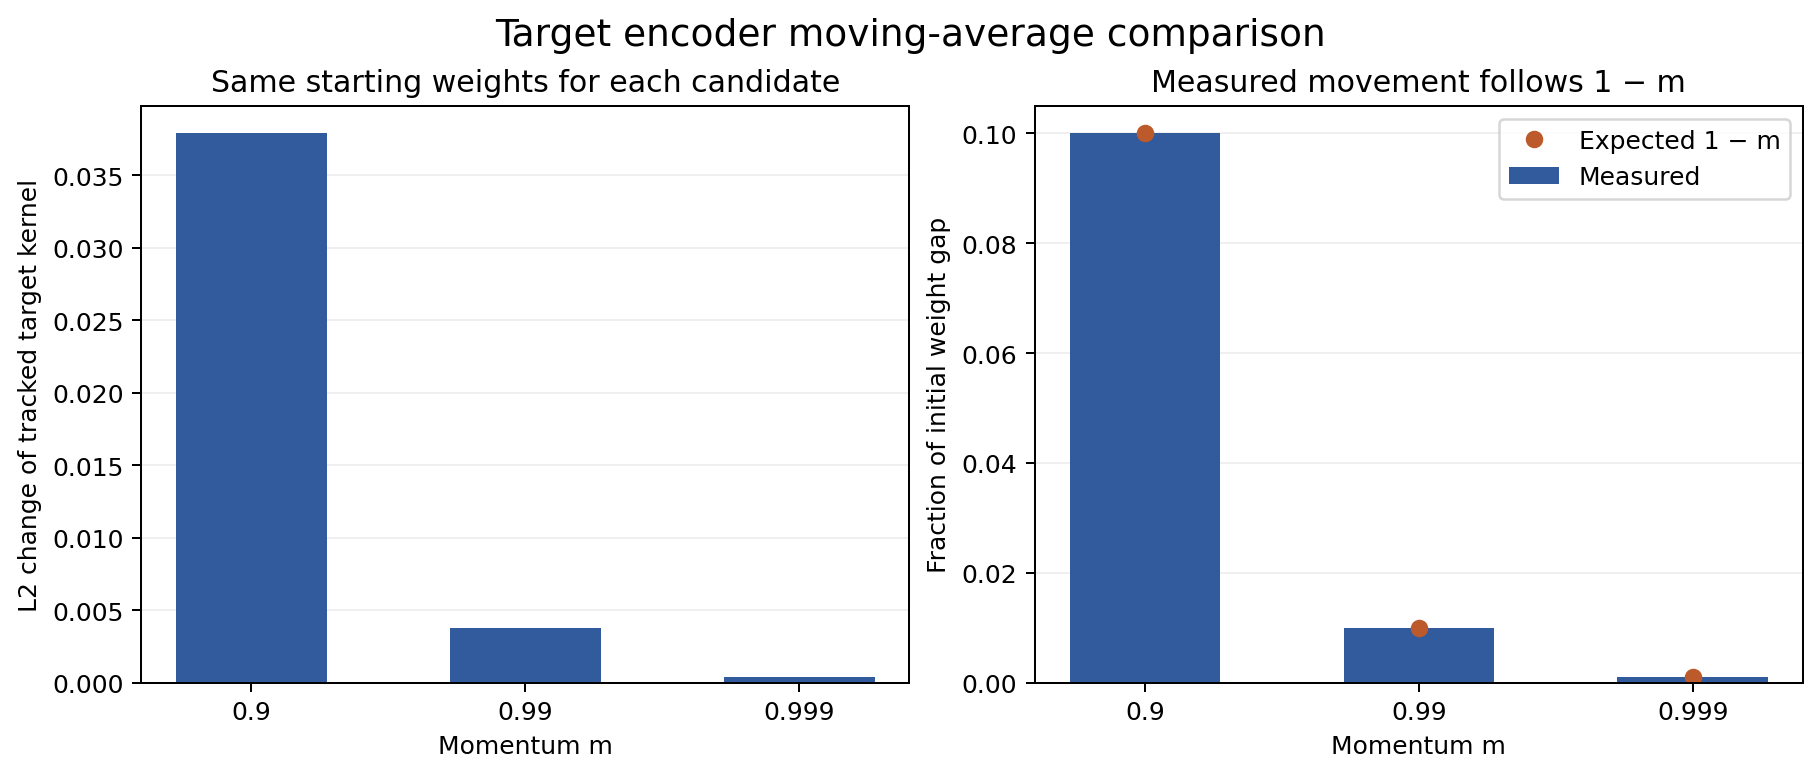

In [6]:
momentum_comparison_measurements = training_step_results["momentum_comparison"]
for momentum_measurement in momentum_comparison_measurements:
    target_weight_movement = momentum_measurement["target_movement_l2"]
    measured_gap_fraction = momentum_measurement["measured_gap_fraction"]
    expected_gap_fraction = momentum_measurement["expected_gap_fraction"]
    print(
        f"m={momentum_measurement['momentum']:<5}  movement={target_weight_movement:.8f}  "
        f"gap fraction={measured_gap_fraction:.6f}"
    )
    # The measured fraction should agree with 1 - momentum.
    assert abs(measured_gap_fraction - expected_gap_fraction) < 1e-4

target_update_figure_path = RESULTS_DIRECTORY / "05_target_update.png"
plot_momentum(momentum_comparison_measurements, target_update_figure_path)
display(Image(filename=str(target_update_figure_path)))

## 6. Mask-size comparison

I compared four target patches with eight while keeping the image and initial model weights fixed. With four target patches, the context encoder has twelve visible positions. With eight target patches, it has eight visible positions.

| Target patches | Context patches | Context attention per head | Query–key pairs per head | Prediction and reference shape |
|---|---|---|---|---|
| 4 | 12 | 12 × 12 | 144 | `(1, 4, 192)` |
| 8 | 8 | 8 × 8 | 64 | `(1, 8, 192)` |

Each visible query is compared with every visible key in the context encoder. Reducing the visible sequence from twelve tokens to eight reduces the number of pairs from 12² to 8² per head. The target encoder still processes all sixteen image patches in each case. The predictor returns four vectors in the first case and eight in the second, one for each requested position.

{
  "target_patches": 4,
  "context_patches": 12,
  "context_attention_shape": [
    12,
    12
  ],
  "context_query_key_pairs_per_head": 144,
  "target_attention_shape": [
    16,
    16
  ],
  "prediction_shape": [
    1,
    4,
    192
  ],
  "reference_shape": [
    1,
    4,
    192
  ]
}
{
  "target_patches": 8,
  "context_patches": 8,
  "context_attention_shape": [
    8,
    8
  ],
  "context_query_key_pairs_per_head": 64,
  "target_attention_shape": [
    16,
    16
  ],
  "prediction_shape": [
    1,
    8,
    192
  ],
  "reference_shape": [
    1,
    8,
    192
  ]
}


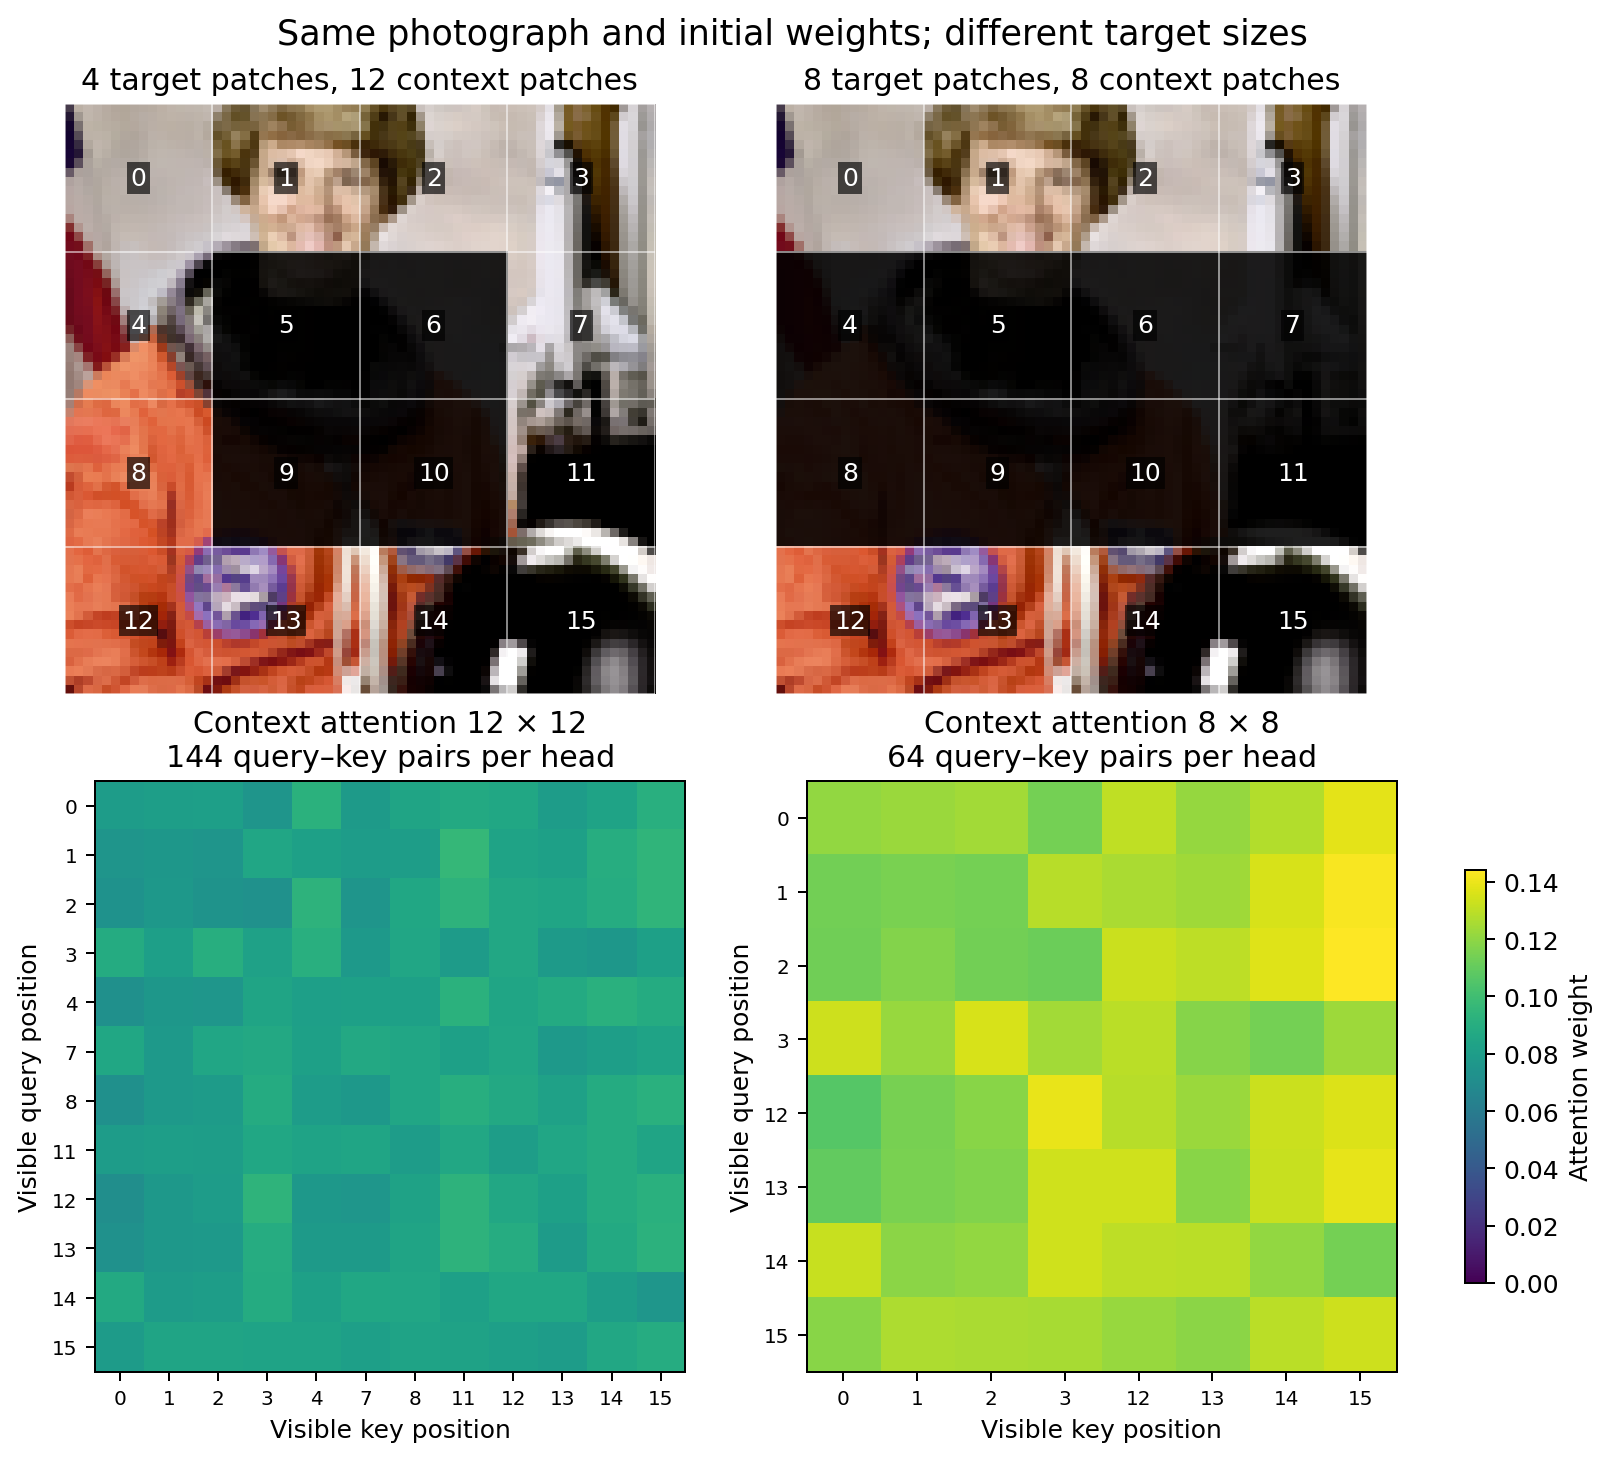

In [7]:
mask_size_measurements, mask_size_visualizations = compare_masks(
    normalized_image_tensor, seed=INITIALIZATION_SEED
)
for mask_measurement in mask_size_measurements:
    print(json.dumps(mask_measurement, indent=2))

visible_context_counts = [
    measurement["context_patches"] for measurement in mask_size_measurements
]
query_key_pairs_per_head = [
    measurement["context_query_key_pairs_per_head"]
    for measurement in mask_size_measurements
]
target_prediction_shapes = [
    measurement["prediction_shape"] for measurement in mask_size_measurements
]
assert visible_context_counts == [12, 8]
assert query_key_pairs_per_head == [144, 64]
assert target_prediction_shapes == [[1, 4, 192], [1, 8, 192]]

mask_comparison_figure_path = RESULTS_DIRECTORY / "06_mask_comparison.png"
plot_mask_comparison(
    resized_crop,
    mask_size_measurements,
    mask_size_visualizations,
    mask_comparison_figure_path,
)
display(Image(filename=str(mask_comparison_figure_path)))

## 7. Saved results

The last cell uses the same `run_lab` function as the command-line script. It starts from the same seed and checks that the loss values, weight changes, and mask measurements agree with the earlier cells. The `outputs` folder contains the six figures and five CSV tables. The JSON summary records the input image, crop coordinates, masks, model settings, and measured results.

In [8]:
command_line_results = run_lab(DEFAULT_IMAGE, RESULTS_DIRECTORY, INITIALIZATION_SEED)
assert command_line_results["baseline_losses"] == baseline_loss_values
assert command_line_results["training_step"] == training_step_results
assert command_line_results["mask_comparison"] == mask_size_measurements

print("Saved six figures, five CSV tables, and results.json.")
print("The command-line entry point reproduced the notebook observations.")
print("Run environment:", json.dumps(command_line_results["environment"], indent=2))

Saved six figures, five CSV tables, and results.json.
The command-line entry point reproduced the notebook observations.
Run environment: {
  "python": "3.12.14",
  "torch": "2.15.0+cpu",
  "numpy": "2.3.5",
  "matplotlib": "3.10.8",
  "pillow": "13.0.0",
  "device": "cpu",
  "torch_threads": 1
}
